
# MovieLens – Item-Based Collaborative Filtering

## Obiettivo

In questo notebook costruiamo la **prima componente del sistema di raccomandazione ibrido**:

- analisi esplorativa del dataset MovieLens;
- studio della distribuzione dei feedback espliciti;
- analisi dell'attività degli utenti e della popolarità dei film;
- studio della sparsità della matrice User–Item;
- costruzione di un modello **Item-Based Collaborative Filtering**;
- ricerca dei film più simili;
- generazione di raccomandazioni personalizzate;
- valutazione offline con metriche Top-N;
- confronto con una baseline di popolarità.

La parte **Content-Based** verrà sviluppata in un notebook separato.

Dataset: **MovieLens Latest Small**, distribuito da GroupLens.



## 1. Import delle librerie


In [1]:

from pathlib import Path
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")



## 2. Download del dataset

Usiamo `ml-latest-small`, che contiene:

- `ratings.csv`: rating espliciti degli utenti;
- `movies.csv`: titolo e generi dei film;
- `tags.csv`: tag assegnati dagli utenti;
- `links.csv`: collegamenti a IMDb e TMDb.

Per la componente **Item-Based** utilizzeremo principalmente `ratings.csv` e `movies.csv`.


In [2]:

DATA_DIR = Path("ml-latest-small")
ZIP_PATH = Path("ml-latest-small.zip")

if not DATA_DIR.exists():
    url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
    print("Download del dataset...")
    urllib.request.urlretrieve(url, ZIP_PATH)

    print("Estrazione...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(".")

    print("Dataset pronto.")
else:
    print("Dataset già presente.")


Download del dataset...
Estrazione...
Dataset pronto.



## 3. Caricamento dei file


In [3]:

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
links = pd.read_csv(DATA_DIR / "links.csv")

print("ratings:", ratings.shape)
print("movies :", movies.shape)
print("tags   :", tags.shape)
print("links  :", links.shape)


ratings: (100836, 4)
movies : (9742, 3)
tags   : (3683, 4)
links  : (9742, 3)


In [4]:

display(ratings.head())
display(movies.head())
display(tags.head())
display(links.head())


,userId,movieId,rating,timestamp
0,1,1,4.0000,964982703
1,1,3,4.0000,964981247
2,1,6,4.0000,964982224
3,1,47,5.0000,964983815
4,1,50,5.0000,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


,movieId,imdbId,tmdbId
0,1,114709,862.0000
1,2,113497,8844.0000
2,3,113228,15602.0000
3,4,114885,31357.0000
4,5,113041,11862.0000



## 4. Studio preliminare del dataset

Per il Collaborative Filtering ci interessano soprattutto le interazioni:

\[
(userId,\ movieId,\ rating)
\]

Il rating è un **feedback esplicito**: l'utente dichiara direttamente il proprio gradimento assegnando un voto al film.


In [5]:

print("RATINGS")
display(ratings.info())

print("\nMOVIES")
display(movies.info())


RATINGS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


None


MOVIES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB


None

In [6]:

print("Numero di utenti:", ratings["userId"].nunique())
print("Numero di film presenti in ratings:", ratings["movieId"].nunique())
print("Numero totale di rating:", len(ratings))
print("Numero di film presenti in movies:", movies["movieId"].nunique())


Numero di utenti: 610
Numero di film presenti in ratings: 9724
Numero totale di rating: 100836
Numero di film presenti in movies: 9742



### 4.1 Valori mancanti


In [7]:

missing = pd.DataFrame({
    "ratings": ratings.isna().sum(),
    "movies": movies.isna().sum()
})

display(missing)


,ratings,movies
genres,NaN,0.0000
movieId,0.0000,0.0000
rating,0.0000,NaN
timestamp,0.0000,NaN
title,NaN,0.0000
userId,0.0000,NaN



### 4.2 Duplicati

Controlliamo che una stessa coppia `userId-movieId` non compaia più volte.


In [8]:

duplicate_ratings = ratings.duplicated(subset=["userId", "movieId"]).sum()

print("Rating duplicati sulla coppia userId-movieId:", duplicate_ratings)
print("Film duplicati per movieId:", movies.duplicated(subset=["movieId"]).sum())


Rating duplicati sulla coppia userId-movieId: 0
Film duplicati per movieId: 0



### 4.3 Conversione del timestamp

Il timestamp non viene utilizzato direttamente dal modello Item-Based, ma ci servirà successivamente per effettuare uno **split temporale train/test**.


In [9]:

ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")

print("Prima interazione:", ratings["datetime"].min())
print("Ultima interazione:", ratings["datetime"].max())

display(ratings.head())


Prima interazione: 1996-03-29 18:36:55
Ultima interazione: 2018-09-24 14:27:30


,userId,movieId,rating,timestamp,datetime
0,1,1,4.0000,964982703,2000-07-30 18:45:03
1,1,3,4.0000,964981247,2000-07-30 18:20:47
2,1,6,4.0000,964982224,2000-07-30 18:37:04
3,1,47,5.0000,964983815,2000-07-30 19:03:35
4,1,50,5.0000,964982931,2000-07-30 18:48:51



# 5. Analisi della distribuzione dei feedback

Prima di costruire il modello analizziamo come gli utenti utilizzano la scala dei rating.


In [10]:

rating_distribution = ratings["rating"].value_counts().sort_index()
rating_percentage = (
    ratings["rating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

rating_stats = pd.DataFrame({
    "numero_rating": rating_distribution,
    "percentuale": rating_percentage
})

display(rating_stats)


,numero_rating,percentuale
rating,,
0.5000,1370,1.3586
1.0000,2811,2.7877
1.5000,1791,1.7762
2.0000,7551,7.4884
2.5000,5550,5.5040
3.0000,20047,19.8808
3.5000,13136,13.0271
4.0000,26818,26.5957
4.5000,8551,8.4801


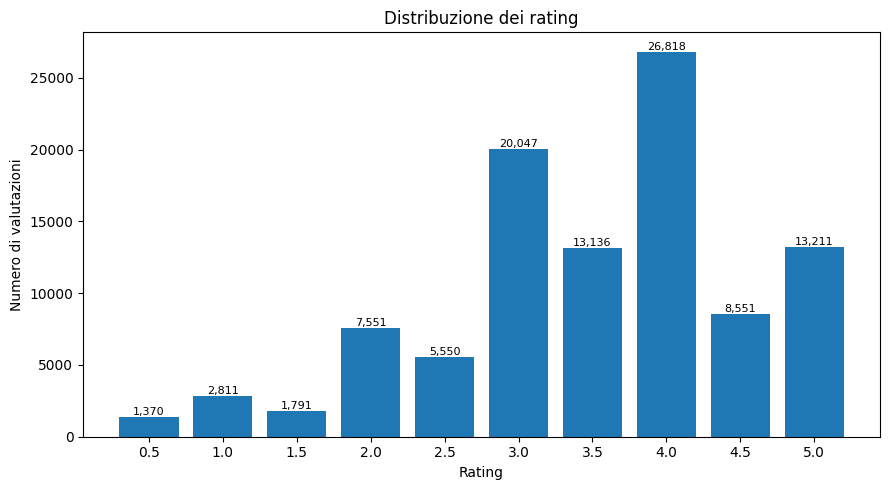

In [11]:

plt.figure(figsize=(9, 5))

bars = plt.bar(
    rating_distribution.index.astype(str),
    rating_distribution.values
)

plt.title("Distribuzione dei rating")
plt.xlabel("Rating")
plt.ylabel("Numero di valutazioni")

for bar, value in zip(bars, rating_distribution.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()


In [12]:

display(ratings["rating"].describe())


,rating
count,100836.0000
mean,3.5016
std,1.0425
min,0.5000
25%,3.0000
50%,3.5000
75%,4.0000
max,5.0000



## 6. Attività degli utenti

Un Collaborative Filtering ha bisogno di una quantità sufficiente di interazioni.  
Studiamo quindi quanti film sono stati valutati da ciascun utente.


In [13]:

ratings_per_user = ratings.groupby("userId").size()

display(ratings_per_user.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))


,0
count,610.0000
mean,165.3049
std,269.4806
min,20.0000
25%,35.0000
50%,70.5000
75%,168.0000
90%,400.3000
95%,610.7500
99%,1256.2200


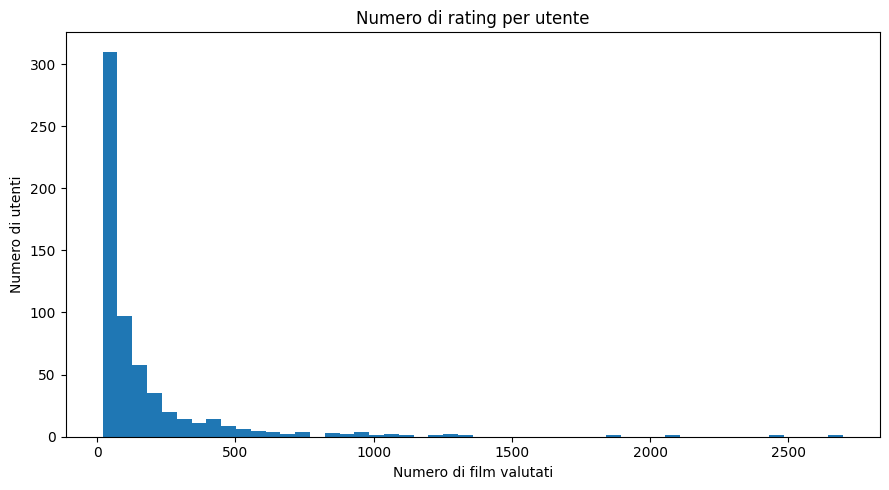

In [14]:

plt.figure(figsize=(9, 5))

plt.hist(ratings_per_user, bins=50)

plt.title("Numero di rating per utente")
plt.xlabel("Numero di film valutati")
plt.ylabel("Numero di utenti")

plt.tight_layout()
plt.show()


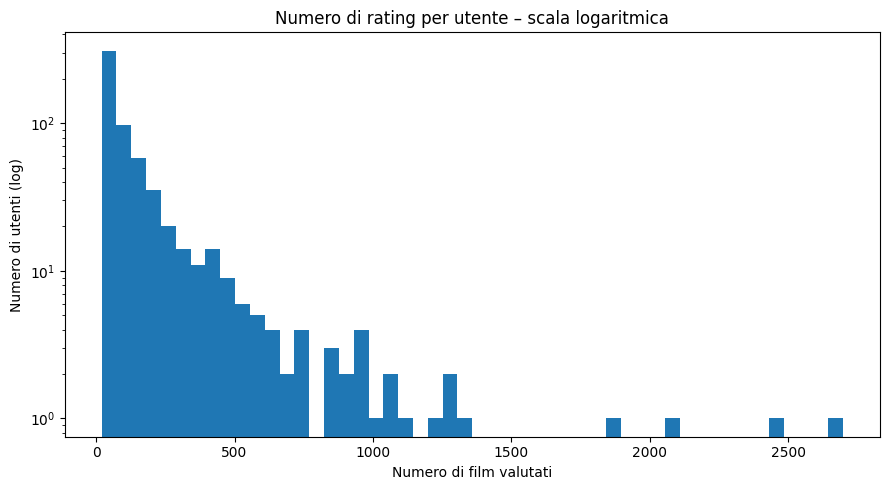

In [15]:

plt.figure(figsize=(9, 5))

plt.hist(ratings_per_user, bins=50)
plt.yscale("log")

plt.title("Numero di rating per utente – scala logaritmica")
plt.xlabel("Numero di film valutati")
plt.ylabel("Numero di utenti (log)")

plt.tight_layout()
plt.show()



## 7. Popolarità dei film

Studiamo ora quanti rating riceve ciascun film.

Questa analisi è particolarmente importante per un modello Item-Based perché i film con pochissimi rating hanno pochi utenti in comune con gli altri item e producono quindi stime di similarità poco affidabili.


In [16]:

ratings_per_movie = ratings.groupby("movieId").size()

display(ratings_per_movie.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))


,0
count,9724.0000
mean,10.3698
std,22.4010
min,1.0000
25%,1.0000
50%,3.0000
75%,9.0000
90%,27.0000
95%,47.0000
99%,114.5400


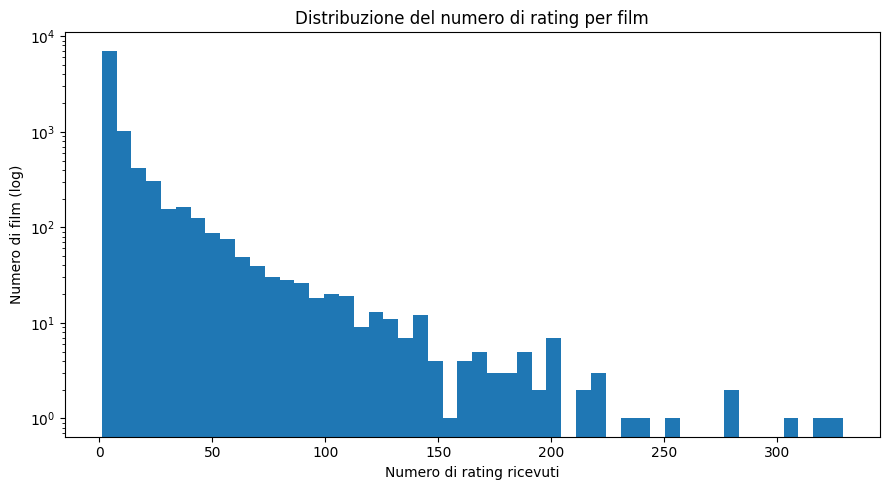

In [17]:

plt.figure(figsize=(9, 5))

plt.hist(ratings_per_movie, bins=50)
plt.yscale("log")

plt.title("Distribuzione del numero di rating per film")
plt.xlabel("Numero di rating ricevuti")
plt.ylabel("Numero di film (log)")

plt.tight_layout()
plt.show()



### 7.1 Statistiche per film


In [18]:

movie_stats = (
    ratings.groupby("movieId")
    .agg(
        num_ratings=("rating", "count"),
        mean_rating=("rating", "mean")
    )
    .reset_index()
    .merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )
)

display(movie_stats.head())


,movieId,num_ratings,mean_rating,title,genres
0,1,215,3.9209,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,110,3.4318,Jumanji (1995),Adventure|Children|Fantasy
2,3,52,3.2596,Grumpier Old Men (1995),Comedy|Romance
3,4,7,2.3571,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,49,3.0714,Father of the Bride Part II (1995),Comedy



### 7.2 Film più popolari

Qui "popolare" significa semplicemente **film con il maggior numero di rating**.


In [19]:

top_popular = (
    movie_stats
    .sort_values("num_ratings", ascending=False)
    .head(20)
)

display(
    top_popular[
        ["movieId", "title", "num_ratings", "mean_rating"]
    ]
)


,movieId,title,num_ratings,mean_rating
314,356,Forrest Gump (1994),329,4.1641
277,318,"Shawshank Redemption, The (1994)",317,4.4290
257,296,Pulp Fiction (1994),307,4.1971
510,593,"Silence of the Lambs, The (1991)",279,4.1613
1938,2571,"Matrix, The (1999)",278,4.1924
224,260,Star Wars: Episode IV - A New Hope (1977),251,4.2311
418,480,Jurassic Park (1993),238,3.7500
97,110,Braveheart (1995),237,4.0316
507,589,Terminator 2: Judgment Day (1991),224,3.9710
461,527,Schindler's List (1993),220,4.2250



### 7.3 Film con rating medio più alto

La sola media può essere ingannevole: un film valutato 5 stelle da un solo utente non è necessariamente più affidabile di un film con media 4.7 e centinaia di rating.

Per questo imponiamo un numero minimo di feedback.


In [20]:

MIN_RATINGS_FOR_TOP = 20

top_rated = (
    movie_stats[
        movie_stats["num_ratings"] >= MIN_RATINGS_FOR_TOP
    ]
    .sort_values(
        ["mean_rating", "num_ratings"],
        ascending=[False, False]
    )
    .head(20)
)

display(
    top_rated[
        ["movieId", "title", "num_ratings", "mean_rating"]
    ]
)


,movieId,title,num_ratings,mean_rating
840,1104,"Streetcar Named Desire, A (1951)",20,4.4750
277,318,"Shawshank Redemption, The (1994)",317,4.4290
704,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),27,4.3333
680,898,"Philadelphia Story, The (1940)",29,4.3103
905,1204,Lawrence of Arabia (1962),45,4.3000
413,475,In the Name of the Father (1993),25,4.3000
210,246,Hoop Dreams (1994),29,4.2931
659,858,"Godfather, The (1972)",192,4.2891
934,1235,Harold and Maude (1971),26,4.2885
9445,168252,Logan (2017),25,4.2800



## 8. Analisi della Long Tail

Ordiniamo i film dal più al meno popolare e osserviamo quanta parte dei rating complessivi viene concentrata su una frazione ridotta del catalogo.


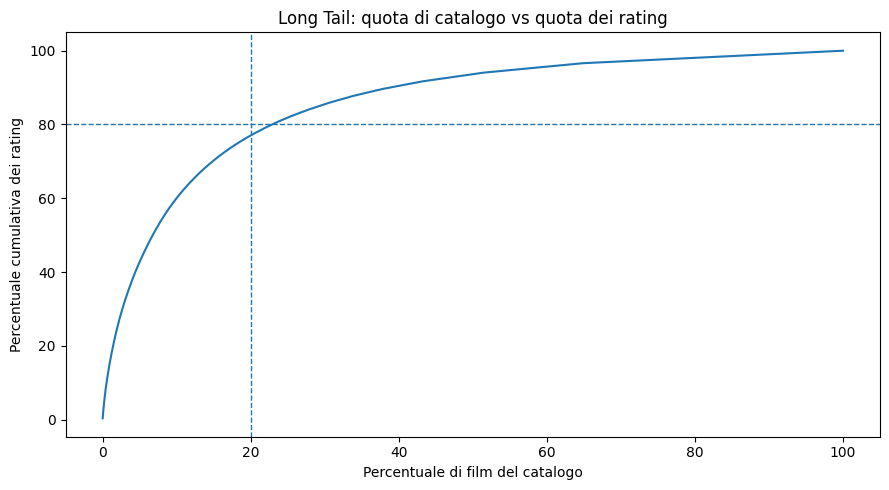

In [21]:

popularity_sorted = ratings_per_movie.sort_values(ascending=False)

catalog_fraction = (
    np.arange(1, len(popularity_sorted) + 1)
    / len(popularity_sorted)
    * 100
)

cumulative_rating_fraction = (
    popularity_sorted.cumsum()
    / popularity_sorted.sum()
    * 100
)

plt.figure(figsize=(9, 5))

plt.plot(catalog_fraction, cumulative_rating_fraction)

plt.axhline(80, linestyle="--", linewidth=1)
plt.axvline(20, linestyle="--", linewidth=1)

plt.title("Long Tail: quota di catalogo vs quota dei rating")
plt.xlabel("Percentuale di film del catalogo")
plt.ylabel("Percentuale cumulativa dei rating")

plt.tight_layout()
plt.show()


In [22]:

share_top_20_catalog = cumulative_rating_fraction.iloc[
    max(int(len(popularity_sorted) * 0.20) - 1, 0)
]

print(
    f"Il 20% dei film più popolari raccoglie circa "
    f"{share_top_20_catalog:.2f}% di tutti i rating."
)


Il 20% dei film più popolari raccoglie circa 77.02% di tutti i rating.



# 9. Matrice User–Item

Costruiamo la matrice:

- righe = utenti;
- colonne = film;
- celle = rating;
- `NaN` = film non valutato dall'utente.


In [23]:

user_item_matrix = ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Shape matrice User-Item:", user_item_matrix.shape)

display(user_item_matrix.iloc[:10, :10])


Shape matrice User-Item: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0000,NaN,4.0000,NaN,NaN,4.0000,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0000,5.0000,3.0000,5.0000,4.0000,4.0000,3.0000,NaN,3.0000
7,4.5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0000
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



## 9.1 Density e Sparsity

La **density** indica la percentuale di celle realmente osservate.

La **sparsity** indica invece la percentuale di celle mancanti:

\[
sparsity = 1 - density
\]


In [24]:

n_users, n_movies_rated = user_item_matrix.shape

n_possible_ratings = n_users * n_movies_rated
n_actual_ratings = user_item_matrix.notna().sum().sum()

density = n_actual_ratings / n_possible_ratings
sparsity = 1 - density

print(f"Utenti: {n_users}")
print(f"Film: {n_movies_rated}")
print(f"Interazioni osservate: {n_actual_ratings:,}")
print(f"Interazioni possibili: {n_possible_ratings:,}")
print(f"Density: {density:.4%}")
print(f"Sparsity: {sparsity:.4%}")


Utenti: 610
Film: 9724
Interazioni osservate: 100,836
Interazioni possibili: 5,931,640
Density: 1.7000%
Sparsity: 98.3000%



# 10. Item-Based Collaborative Filtering

L'obiettivo è calcolare quanto due film siano simili **in base al comportamento degli utenti**.

Non stiamo confrontando genere, trama o attori.  
Due film risultano simili se tendono a ricevere valutazioni coerenti dagli stessi utenti.

## 10.1 Mean-centering

Utenti diversi possono utilizzare la scala dei rating in modo diverso.

Esempio:

- un utente assegna quasi sempre voti tra 4 e 5;
- un altro utente assegna quasi sempre voti tra 2.5 e 4.

Per ridurre questo effetto sottraiamo, a ogni rating, la media dei rating dell'utente:

\[
r'_{u,i} = r_{u,i} - \\bar{r}_u
\]

Successivamente calcoliamo la **cosine similarity** tra i vettori degli item.



## 10.2 Funzione per costruire il modello

Introduciamo due soglie:

- `min_ratings_per_movie`: un film deve avere un minimo di rating per entrare nel modello;
- `min_common_users`: due film devono avere un minimo di utenti in comune affinché la loro similarità venga considerata valida.

Le soglie servono a evitare similarità elevate calcolate su pochissime osservazioni.


In [25]:

def build_item_cf(
    ratings_df,
    min_ratings_per_movie=10,
    min_common_users=5
):
    # 1. Filtriamo i film con troppo pochi rating
    movie_counts = ratings_df.groupby("movieId").size()

    eligible_movies = movie_counts[
        movie_counts >= min_ratings_per_movie
    ].index

    data = ratings_df[
        ratings_df["movieId"].isin(eligible_movies)
    ].copy()

    # 2. Matrice User-Item
    matrix = data.pivot(
        index="userId",
        columns="movieId",
        values="rating"
    )

    # 3. Media dei rating di ogni utente
    user_means = matrix.mean(axis=1)

    # 4. Mean-centering
    centered = matrix.sub(user_means, axis=0)

    movie_ids = matrix.columns.to_numpy()

    # 5. Matrice Item-User.
    # I NaN diventano 0 DOPO il mean-centering:
    # 0 significa quindi "nessun contributo".
    item_user = (
        centered
        .T
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    # 6. Adjusted cosine similarity
    similarity = cosine_similarity(
        item_user
    ).astype(np.float32)

    # 7. Numero di utenti che hanno valutato entrambe le coppie di film
    binary_ratings = (
        matrix
        .notna()
        .T
        .to_numpy(dtype=np.int16)
    )

    common_users = binary_ratings @ binary_ratings.T

    # 8. Eliminiamo le similarità calcolate su troppo pochi utenti comuni
    similarity[
        common_users < min_common_users
    ] = 0.0

    # Un film non deve essere considerato vicino di sé stesso
    np.fill_diagonal(similarity, 0.0)

    movie_to_pos = {
        movie_id: pos
        for pos, movie_id in enumerate(movie_ids)
    }

    return {
        "ratings": data,
        "matrix": matrix,
        "centered": centered,
        "user_means": user_means,
        "movie_ids": movie_ids,
        "movie_to_pos": movie_to_pos,
        "similarity": similarity,
        "common_users": common_users,
        "min_ratings_per_movie": min_ratings_per_movie,
        "min_common_users": min_common_users,
    }



## 10.3 Addestramento del modello sull'intero dataset

Questa versione viene usata per l'analisi qualitativa e per provare le raccomandazioni.

Per la valutazione costruiremo successivamente un nuovo modello utilizzando **solo il training set**.


In [26]:

MIN_RATINGS_PER_MOVIE = 10
MIN_COMMON_USERS = 5

item_model = build_item_cf(
    ratings,
    min_ratings_per_movie=MIN_RATINGS_PER_MOVIE,
    min_common_users=MIN_COMMON_USERS
)

print(
    "Film presenti nel modello:",
    len(item_model["movie_ids"])
)

print(
    "Utenti presenti nel modello:",
    len(item_model["matrix"])
)

print(
    "Shape matrice di similarità:",
    item_model["similarity"].shape
)


Film presenti nel modello: 2269
Utenti presenti nel modello: 610
Shape matrice di similarità: (2269, 2269)



# 11. Ricerca dei film più simili


In [27]:

movie_lookup = movies.set_index("movieId")

def search_movie(query, n=20):
    mask = movies["title"].str.contains(
        query,
        case=False,
        regex=False,
        na=False
    )

    return movies.loc[
        mask,
        ["movieId", "title", "genres"]
    ].head(n)


In [28]:

search_movie("Toy Story")


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2355,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
7355,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX


In [29]:

def similar_movies(model, movie_id, n=10):
    if movie_id not in model["movie_to_pos"]:
        raise ValueError(
            "Il film non è presente nel catalogo del modello. "
            "Potrebbe avere troppo pochi rating."
        )

    pos = model["movie_to_pos"][movie_id]

    sims = model["similarity"][pos]
    common = model["common_users"][pos]

    order = np.argsort(sims)[::-1]

    rows = []

    for other_pos in order:
        if sims[other_pos] <= 0:
            continue

        other_movie_id = model["movie_ids"][other_pos]

        rows.append({
            "movieId": other_movie_id,
            "title": movie_lookup.loc[other_movie_id, "title"],
            "similarity": float(sims[other_pos]),
            "common_users": int(common[other_pos])
        })

        if len(rows) == n:
            break

    return pd.DataFrame(rows)


In [30]:

# Toy Story (1995) ha movieId = 1
similar_movies(item_model, movie_id=1, n=10)


,movieId,title,similarity,common_users
0,3114,Toy Story 2 (1999),0.3727,81
1,588,Aladdin (1992),0.2983,107
2,78499,Toy Story 3 (2010),0.2948,44
3,1148,Wallace & Gromit: The Wrong Trousers (1993),0.2797,40
4,8961,"Incredibles, The (2004)",0.2464,77
5,6377,Finding Nemo (2003),0.2376,87
6,1270,Back to the Future (1985),0.2364,106
7,3671,Blazing Saddles (1974),0.2332,39
8,34,Babe (1995),0.2112,84
9,364,"Lion King, The (1994)",0.2107,107



## Interpretazione

Questa tabella non dice che due film sono simili perché appartengono allo stesso genere.

Dice invece che:

> gli utenti che hanno espresso determinate preferenze per il film di partenza tendono a esprimere preferenze simili anche per i film restituiti.

Questa è la logica del **Collaborative Filtering Item-Based**.



# 12. Raccomandazioni personalizzate

Per raccomandare film a un utente utilizziamo i film che ha già valutato.

Per ogni film candidato \(j\), stimiamo il rating:

\[
\hat r_{u,j}
=
\\bar r_u
+
\\frac{
\sum_{i \\in I_u}
sim(j,i)(r_{u,i}-\\bar r_u)
}{
\sum_{i \\in I_u}|sim(j,i)|
}
\]

dove:

- \(I_u\) = film già valutati dall'utente;
- \(sim(j,i)\) = similarità Item-Item;
- \(\bar r_u\) = rating medio dell'utente.

Utilizziamo al massimo i `K` item già valutati più simili al candidato.


In [31]:

def recommend_for_user(
    model,
    user_id,
    n=10,
    k_neighbors=30
):
    matrix = model["matrix"]

    if user_id not in matrix.index:
        raise ValueError(
            "Utente non presente nel modello."
        )

    row = matrix.loc[user_id]

    seen = row.dropna()

    if len(seen) == 0:
        return pd.DataFrame()

    seen_movie_ids = seen.index.to_numpy()

    seen_positions = np.array([
        model["movie_to_pos"][movie_id]
        for movie_id in seen_movie_ids
    ])

    user_mean = model["user_means"].loc[user_id]

    deviations = (
        seen.to_numpy(dtype=np.float32)
        - user_mean
    )

    # Similarità di ogni film candidato
    # rispetto ai film già valutati dall'utente
    S = model["similarity"][:, seen_positions]

    if S.shape[1] > k_neighbors:
        # Per ogni candidato selezioniamo i K vicini
        # con maggiore similarità in valore assoluto.
        top_idx = np.argpartition(
            np.abs(S),
            -k_neighbors,
            axis=1
        )[:, -k_neighbors:]

        top_sims = np.take_along_axis(
            S,
            top_idx,
            axis=1
        )

        top_deviations = deviations[top_idx]

        numerator = (
            top_sims * top_deviations
        ).sum(axis=1)

        denominator = np.abs(
            top_sims
        ).sum(axis=1)

        n_neighbors = (
            top_sims != 0
        ).sum(axis=1)

    else:
        numerator = (
            S * deviations
        ).sum(axis=1)

        denominator = np.abs(S).sum(axis=1)

        n_neighbors = (
            S != 0
        ).sum(axis=1)

    predictions = np.full(
        len(model["movie_ids"]),
        np.nan,
        dtype=np.float32
    )

    valid = denominator > 0

    predictions[valid] = (
        user_mean
        + numerator[valid] / denominator[valid]
    )

    # Manteniamo le predizioni entro la scala MovieLens
    predictions = np.clip(
        predictions,
        0.5,
        5.0
    )

    # Escludiamo i film già valutati
    seen_positions_set = set(seen_positions.tolist())

    candidate_positions = [
        pos
        for pos in range(len(model["movie_ids"]))
        if pos not in seen_positions_set
        and np.isfinite(predictions[pos])
    ]

    candidate_positions = sorted(
        candidate_positions,
        key=lambda pos: predictions[pos],
        reverse=True
    )[:n]

    rows = []

    for pos in candidate_positions:
        movie_id = model["movie_ids"][pos]

        rows.append({
            "movieId": movie_id,
            "title": movie_lookup.loc[movie_id, "title"],
            "predicted_rating": float(predictions[pos]),
            "neighbors_used": int(n_neighbors[pos])
        })

    return pd.DataFrame(rows)



## 12.1 Profilo di un utente di esempio


In [32]:

USER_ID = 1

user_history = (
    ratings[
        ratings["userId"] == USER_ID
    ]
    .merge(
        movies[["movieId", "title"]],
        on="movieId",
        how="left"
    )
    .sort_values("rating", ascending=False)
)

display(user_history.head(20))


,userId,movieId,rating,timestamp,datetime,title
3,1,47,5.0000,964983815,2000-07-30 19:03:35,Seven (a.k.a. Se7en) (1995)
4,1,50,5.0000,964982931,2000-07-30 18:48:51,"Usual Suspects, The (1995)"
6,1,101,5.0000,964980868,2000-07-30 18:14:28,Bottle Rocket (1996)
13,1,231,5.0000,964981179,2000-07-30 18:19:39,Dumb & Dumber (Dumb and Dumber) (1994)
11,1,216,5.0000,964981208,2000-07-30 18:20:08,Billy Madison (1995)
10,1,163,5.0000,964983650,2000-07-30 19:00:50,Desperado (1995)
9,1,157,5.0000,964984100,2000-07-30 19:08:20,Canadian Bacon (1995)
8,1,151,5.0000,964984041,2000-07-30 19:07:21,Rob Roy (1995)
35,1,596,5.0000,964982838,2000-07-30 18:47:18,Pinocchio (1940)
31,1,553,5.0000,964984153,2000-07-30 19:09:13,Tombstone (1993)



## 12.2 Top-N raccomandazioni


In [33]:

recommendations = recommend_for_user(
    item_model,
    user_id=USER_ID,
    n=10,
    k_neighbors=30
)

display(recommendations)


,movieId,title,predicted_rating,neighbors_used
0,7147,Big Fish (2003),5.0000,30
1,1748,Dark City (1998),4.9737,30
2,2300,"Producers, The (1968)",4.9693,30
3,2890,Three Kings (1999),4.9564,30
4,1022,Cinderella (1950),4.9526,30
5,96821,"Perks of Being a Wallflower, The (2012)",4.9520,30
6,2324,Life Is Beautiful (La Vita è bella) (1997),4.9398,30
7,1223,"Grand Day Out with Wallace and Gromit, A (1989)",4.9333,30
8,3507,"Odd Couple, The (1968)",4.9329,30
9,5377,About a Boy (2002),4.9297,30



# 13. Baseline di popolarità

Prima della valutazione definiamo una baseline molto semplice:

> raccomandare a ogni utente i film più popolari che non ha ancora visto.

Il nostro Item-Based dovrebbe essere confrontato almeno con questa strategia.


In [34]:

def popularity_recommendations(
    train_ratings,
    user_id,
    candidate_movie_ids,
    n=10
):
    seen = set(
        train_ratings.loc[
            train_ratings["userId"] == user_id,
            "movieId"
        ]
    )

    popularity = (
        train_ratings[
            train_ratings["movieId"].isin(candidate_movie_ids)
        ]
        .groupby("movieId")
        .size()
        .sort_values(ascending=False)
    )

    recs = [
        movie_id
        for movie_id in popularity.index
        if movie_id not in seen
    ][:n]

    return recs



# 14. Valutazione offline

Per evitare leakage utilizziamo uno **split temporale Leave-One-Out**:

1. per ciascun utente ordiniamo le interazioni nel tempo;
2. l'ultima interazione diventa test;
3. tutte le interazioni precedenti diventano training.

Consideriamo rilevante un film di test se il rating assegnato è **almeno 4.0**.

Questo ci permette di valutare il problema come **Top-N Recommendation**.


In [35]:

ratings_sorted = ratings.sort_values(
    ["userId", "timestamp"]
)

test_indices = (
    ratings_sorted
    .groupby("userId")
    .tail(1)
    .index
)

test_ratings = ratings_sorted.loc[
    test_indices
].copy()

train_ratings = ratings_sorted.drop(
    index=test_indices
).copy()

print("Training interactions:", len(train_ratings))
print("Test interactions:", len(test_ratings))

display(test_ratings.head())


Training interactions: 100226
Test interactions: 610


,userId,movieId,rating,timestamp,datetime
161,1,2492,4.0000,965719662,2000-08-08 07:27:42
247,2,80489,4.5000,1445715340,2015-10-24 19:35:40
281,3,2424,0.5000,1306464293,2011-05-27 02:44:53
502,4,4246,4.0000,1007574542,2001-12-05 17:49:02
545,5,474,4.0000,847435337,1996-11-08 06:42:17



## 14.1 Costruzione del modello esclusivamente sul training set


In [36]:

eval_model = build_item_cf(
    train_ratings,
    min_ratings_per_movie=MIN_RATINGS_PER_MOVIE,
    min_common_users=MIN_COMMON_USERS
)

print(
    "Film nel modello di evaluation:",
    len(eval_model["movie_ids"])
)


Film nel modello di evaluation: 2262



## 14.2 Utenti valutabili

Valutiamo soltanto i casi in cui:

- l'ultima interazione dell'utente ha rating >= 4;
- l'utente è presente nel training set;
- il film di test è presente nel catalogo del modello dopo il filtro di popolarità.

Stampiamo anche quanti utenti vengono effettivamente valutati, così la copertura del protocollo resta trasparente.


In [37]:

RELEVANCE_THRESHOLD = 4.0

positive_test = test_ratings[
    test_ratings["rating"] >= RELEVANCE_THRESHOLD
].copy()

eligible_users = []

for _, row in positive_test.iterrows():
    user_id = row["userId"]
    movie_id = row["movieId"]

    if (
        user_id in eval_model["matrix"].index
        and movie_id in eval_model["movie_to_pos"]
    ):
        eligible_users.append(user_id)

eligible_users = sorted(set(eligible_users))

print("Utenti totali:", ratings["userId"].nunique())
print(
    "Utenti con ultimo rating >= 4:",
    positive_test["userId"].nunique()
)
print(
    "Utenti effettivamente valutabili:",
    len(eligible_users)
)


Utenti totali: 610
Utenti con ultimo rating >= 4: 363
Utenti effettivamente valutabili: 289



## 14.3 Funzioni di evaluation

Calcoliamo:

- **HitRate@K**: percentuale di utenti per cui il film rilevante compare nella Top-K;
- **Precision@K**: quota media di elementi rilevanti nella lista raccomandata;
- **Recall@K**: quota degli item rilevanti recuperati;
- **MRR@K**: premia i casi in cui il film rilevante appare nelle prime posizioni;
- **NDCG@K**: misura la qualità della posizione dell'item rilevante;
- **CatalogCoverage@K**: percentuale del catalogo che compare almeno una volta nelle raccomandazioni.

Con un solo item rilevante per utente, **HitRate@K e Recall@K coincidono numericamente**.


In [38]:

def recommendation_ids_for_user(
    model,
    user_id,
    n=10,
    k_neighbors=30
):
    recs = recommend_for_user(
        model,
        user_id=user_id,
        n=n,
        k_neighbors=k_neighbors
    )

    if recs.empty:
        return []

    return recs["movieId"].tolist()


def evaluate_recommender(
    get_recommendations,
    test_df,
    users,
    catalog_movie_ids,
    k=10
):
    test_lookup = (
        test_df
        .set_index("userId")["movieId"]
        .to_dict()
    )

    hits = []
    reciprocal_ranks = []
    ndcgs = []
    all_recommended = set()

    evaluated = 0

    for user_id in users:
        true_movie = test_lookup[user_id]

        recs = get_recommendations(
            user_id,
            k
        )

        if len(recs) == 0:
            continue

        evaluated += 1
        all_recommended.update(recs)

        if true_movie in recs:
            rank = recs.index(true_movie) + 1

            hits.append(1)
            reciprocal_ranks.append(1 / rank)
            ndcgs.append(1 / np.log2(rank + 1))
        else:
            hits.append(0)
            reciprocal_ranks.append(0)
            ndcgs.append(0)

    if evaluated == 0:
        raise ValueError(
            "Nessun utente valutabile."
        )

    hit_rate = np.mean(hits)
    precision = np.sum(hits) / (evaluated * k)
    recall = hit_rate
    mrr = np.mean(reciprocal_ranks)
    ndcg = np.mean(ndcgs)

    coverage = (
        len(all_recommended)
        / len(catalog_movie_ids)
    )

    return {
        "n_utenti_valutati": evaluated,
        f"HitRate@{k}": hit_rate,
        f"Precision@{k}": precision,
        f"Recall@{k}": recall,
        f"MRR@{k}": mrr,
        f"NDCG@{k}": ndcg,
        f"CatalogCoverage@{k}": coverage
    }



## 14.4 Evaluation dell'Item-Based


In [39]:

K = 10

def item_based_get_recs(user_id, k):
    return recommendation_ids_for_user(
        eval_model,
        user_id=user_id,
        n=k,
        k_neighbors=30
    )

item_metrics = evaluate_recommender(
    get_recommendations=item_based_get_recs,
    test_df=positive_test,
    users=eligible_users,
    catalog_movie_ids=eval_model["movie_ids"],
    k=K
)

item_metrics_df = pd.DataFrame(
    item_metrics,
    index=["Item-Based"]
).T

display(item_metrics_df)


,Item-Based
n_utenti_valutati,289.0000
HitRate@10,0.0104
Precision@10,0.0010
Recall@10,0.0104
MRR@10,0.0015
NDCG@10,0.0035
CatalogCoverage@10,0.4509



## 14.5 Evaluation della baseline di popolarità


In [40]:

def popularity_get_recs(user_id, k):
    return popularity_recommendations(
        train_ratings,
        user_id=user_id,
        candidate_movie_ids=eval_model["movie_ids"],
        n=k
    )

pop_metrics = evaluate_recommender(
    get_recommendations=popularity_get_recs,
    test_df=positive_test,
    users=eligible_users,
    catalog_movie_ids=eval_model["movie_ids"],
    k=K
)

pop_metrics_df = pd.DataFrame(
    pop_metrics,
    index=["Popularity"]
).T

display(pop_metrics_df)


,Popularity
n_utenti_valutati,289.0000
HitRate@10,0.0796
Precision@10,0.0080
Recall@10,0.0796
MRR@10,0.0249
NDCG@10,0.0376
CatalogCoverage@10,0.0367



# 15. Confronto Item-Based vs baseline


In [41]:

comparison = pd.DataFrame({
    "Item-Based": item_metrics,
    "Popularity": pop_metrics
})

display(comparison)


,Item-Based,Popularity
n_utenti_valutati,289.0000,289.0000
HitRate@10,0.0104,0.0796
Precision@10,0.0010,0.0080
Recall@10,0.0104,0.0796
MRR@10,0.0015,0.0249
NDCG@10,0.0035,0.0376
CatalogCoverage@10,0.4509,0.0367


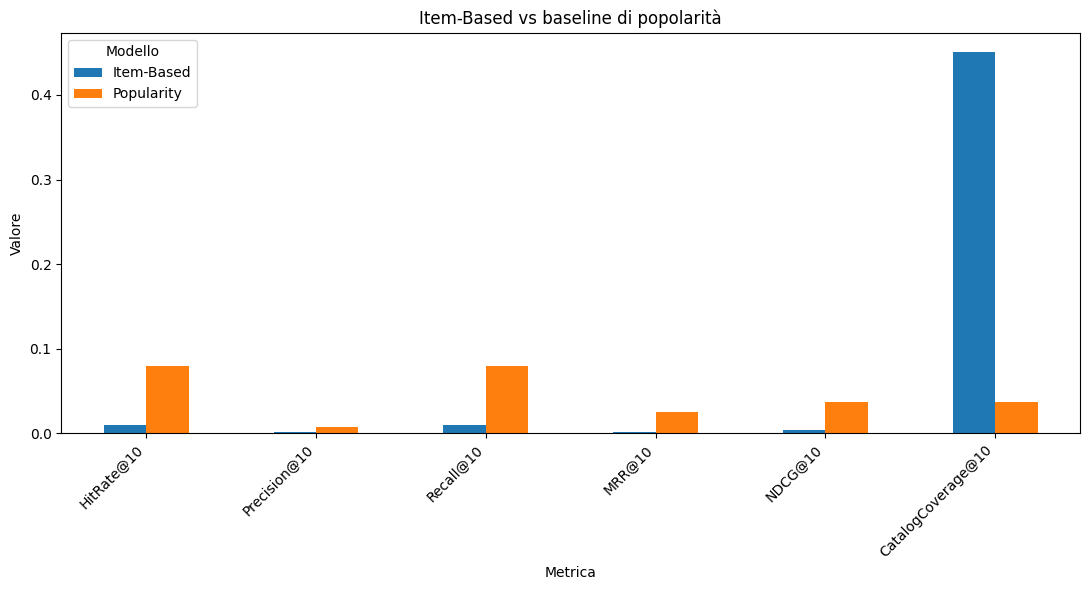

In [42]:

metric_names = [
    f"HitRate@{K}",
    f"Precision@{K}",
    f"Recall@{K}",
    f"MRR@{K}",
    f"NDCG@{K}",
    f"CatalogCoverage@{K}"
]

plot_df = comparison.loc[metric_names]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Item-Based vs baseline di popolarità")
plt.ylabel("Valore")
plt.xlabel("Metrica")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Modello")

plt.tight_layout()
plt.show()



# 16. Considerazioni finali

A questo punto abbiamo una pipeline Item-Based completa:

1. analisi dei rating;
2. analisi della distribuzione delle interazioni;
3. studio della Long Tail;
4. costruzione della matrice User–Item;
5. misura della sparsità;
6. mean-centering dei rating;
7. adjusted cosine similarity tra item;
8. filtro sul numero minimo di rating;
9. filtro sul numero minimo di utenti in comune;
10. film simili;
11. raccomandazioni personalizzate;
12. split temporale;
13. valutazione Top-N;
14. confronto con una baseline.

## Passo successivo

Nel secondo notebook costruiremo il **Content-Based Filtering**, utilizzando le caratteristiche dei film disponibili in MovieLens, in particolare:

- `genres`;
- `tags`.

Successivamente normalizzeremo gli score dei due modelli e costruiremo il sistema **Hybrid**:

\[
Score_{Hybrid}(u,i)
=
\\alpha Score_{CF}(u,i)
+
(1-\\alpha)Score_{CB}(u,i)
\]
